In [79]:
%pip install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
import zipfile
from pathlib import Path

In [81]:
# --- Folders --------------------------------------------------------------
DATA_DIR = Path("../data")      # raw and clean CSV files go here
FIG_DIR = Path("../figures")    # exported plots go here
DATA_DIR.mkdir(exist_ok=True)  # create the folder if it does not exist yet
FIG_DIR.mkdir(exist_ok=True)

# --- pandas display options -------------------------------------------------
pd.set_option("display.max_columns", 50)                 # show every column, do not hide them with "..."
pd.set_option("display.float_format", "{:,.2f}".format)  # 1234567.891 -> 1,234,567.89

# --- plot style -------------------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")  # clean background with a light grid
plt.rcParams["figure.figsize"] = (10, 5)              # default size of every figure (width, height) in inches

# Seed for anything random (sampling): the same seed always gives the same "random" result,
# so everybody in class sees exactly the same numbers.
RANDOM_STATE = 33


def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR.
    # dpi = dots per inch (resolution). bbox_inches="tight" trims empty white borders.
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

In [82]:
# Download (or reuse from the cache) the CSV file
csv_path = kh.dataset_download(
    "harlfoxem/housesalesprediction",
    path="kc_house_data.csv",
)

# Check if the file is zipped
is_zip = zipfile.is_zipfile(csv_path)

# Read CSV
df = pd.read_csv(
    csv_path,
    compression="zip" if is_zip else None
)

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")


Loaded 21,613 rows and 21 columns


In [83]:
raw_path = DATA_DIR / "kc_house_data_raw.csv"

# Writing 100+ MB takes a few seconds, so we only do it the first time
if not raw_path.exists():
    df.to_csv(raw_path, index=False)  # index=False: do not write pandas' row numbers as an extra column
    print(f"Raw data saved to {raw_path}")
else:
    print(f"Raw data already saved in {raw_path}")

Raw data already saved in ..\data\kc_house_data_raw.csv


In [84]:
df.shape

(21613, 21)

In [85]:
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,"221,900.00",3,1.00,1180,5650,1.00,0,0,3,7,1180,0,1955,0,98178,47.51,-122.26,1340,5650
1,6414100192,20141209T000000,"538,000.00",3,2.25,2570,7242,2.00,0,0,3,7,2170,400,1951,1991,98125,47.72,-122.32,1690,7639
2,5631500400,20150225T000000,"180,000.00",2,1.00,770,10000,1.00,0,0,3,6,770,0,1933,0,98028,47.74,-122.23,2720,8062
3,2487200875,20141209T000000,"604,000.00",4,3.00,1960,5000,1.00,0,0,5,7,1050,910,1965,0,98136,47.52,-122.39,1360,5000
4,1954400510,20150218T000000,"510,000.00",3,2.00,1680,8080,1.00,0,0,3,8,1680,0,1987,0,98074,47.62,-122.05,1800,7503


In [86]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long           21

In [87]:
df.describe(include="all")

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,"21,613.00",21613,"21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00","21,613.00"
unique,NaN,372,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,20140623T000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,142,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,"4,580,301,520.86",NaN,"540,088.14",3.37,2.11,"2,079.90","15,106.97",1.49,0.01,0.23,3.41,7.66,"1,788.39",291.51,"1,971.01",84.40,"98,077.94",47.56,-122.21,"1,986.55","12,768.46"
std,"2,876,565,571.31",NaN,"367,127.20",0.93,0.77,918.44,"41,420.51",0.54,0.09,0.77,0.65,1.18,828.09,442.58,29.37,401.68,53.51,0.14,0.14,685.39,"27,304.18"
min,"1,000,102.00",NaN,"75,000.00",0.00,0.00,290.00,520.00,1.00,0.00,0.00,1.00,1.00,290.00,0.00,"1,900.00",0.00,"98,001.00",47.16,-122.52,399.00,651.00
25%,"2,123,049,194.00",NaN,"321,950.00",3.00,1.75,"1,427.00","5,040.00",1.00,0.00,0.00,3.00,7.00,"1,190.00",0.00,"1,951.00",0.00,"98,033.00",47.47,-122.33,"1,490.00","5,100.00"
50%,"3,904,930,410.00",NaN,"450,000.00",3.00,2.25,"1,910.00","7,618.00",1.50,0.00,0.00,3.00,7.00,"1,560.00",0.00,"1,975.00",0.00,"98,065.00",47.57,-122.23,"1,840.00","7,620.00"
75%,"7,308,900,445.00",NaN,"645,000.00",4.00,2.50,"2,550.00","10,688.00",2.00,0.00,0.00,4.00,8.00,"2,210.00",560.00,"1,997.00",0.00,"98,118.00",47.68,-122.12,"2,360.00","10,083.00"


In [88]:
df_clean = df.copy()

In [89]:
# .duplicated() returns True for every row that is an exact copy of an earlier row
n_duplicates = df_clean.duplicated().sum()   # True counts as 1, False as 0
print(f"Exact duplicated rows: {n_duplicates:,}")

Exact duplicated rows: 0


In [90]:
# Is the index column unique? (every value different)
print(f"Is 'id' unique? {df_clean['id'].is_unique}")

# Look for duplicates in all the other columns
n_duplicates = df_clean.drop(columns="id").duplicated().sum()
share = n_duplicates / len(df_clean)
print(f"Duplicated rows when ignoring 'id': {n_duplicates:,} ({share:.0%} of the dataset!)")

Is 'id' unique? False
Duplicated rows when ignoring 'id': 0 (0% of the dataset!)


In [91]:
def missing_report(data):
    # Return a table with the number and percentage of missing values per column,
    # sorted from most to least missing.
    n_missing = data.isna().sum()                   # count of NaN per column
    pct_missing = data.isna().mean() * 100          # mean of True/False = share of NaN
    report = pd.DataFrame({"n_missing": n_missing, "pct_missing": pct_missing})
    return report.sort_values("pct_missing", ascending=False)


missing = missing_report(df_clean)
missing

,n_missing,pct_missing
id,0,0.00
date,0,0.00
price,0,0.00
bedrooms,0,0.00
bathrooms,0,0.00
sqft_living,0,0.00
sqft_lot,0,0.00
floors,0,0.00
waterfront,0,0.00
view,0,0.00


Figure saved to ..\figures\01_missing_values.png


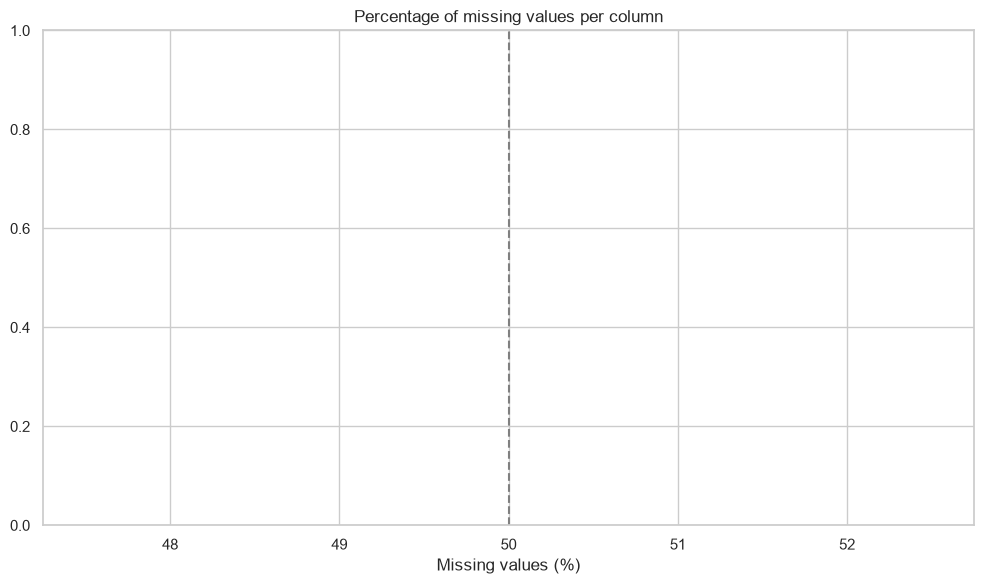

In [92]:
fig, ax = plt.subplots(figsize=(10, 6))

# Only plot the columns that have at least one missing value
missing_to_plot = missing[missing["pct_missing"] > 0]

sns.barplot(data=missing_to_plot, x="pct_missing", y=missing_to_plot.index, color="tab:red", ax=ax)
ax.axvline(50, color="grey", linestyle="--")   # reference line at 50%
ax.set_title("Percentage of missing values per column")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
plt.tight_layout()
save_fig("01_missing_values")
plt.show()

In [93]:
columns_to_drop = ["waterfront", "view"]

df_clean = df_clean.drop(columns=columns_to_drop)
print(f"Remaining columns ({df_clean.shape[1]}): {df_clean.columns.tolist()}")

Remaining columns (19): ['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


In [94]:
df_clean["date"] = pd.to_datetime(df_clean['date'], format='%Y%m%dT%H%M%S')


In [95]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id             21613 non-null  int64         
 1   date           21613 non-null  datetime64[us]
 2   price          21613 non-null  float64       
 3   bedrooms       21613 non-null  int64         
 4   bathrooms      21613 non-null  float64       
 5   sqft_living    21613 non-null  int64         
 6   sqft_lot       21613 non-null  int64         
 7   floors         21613 non-null  float64       
 8   condition      21613 non-null  int64         
 9   grade          21613 non-null  int64         
 10  sqft_above     21613 non-null  int64         
 11  sqft_basement  21613 non-null  int64         
 12  yr_built       21613 non-null  int64         
 13  yr_renovated   21613 non-null  int64         
 14  zipcode        21613 non-null  int64         
 15  lat            21613 non-null 

Figure saved to ..\figures\02_b4Percentile_values.png


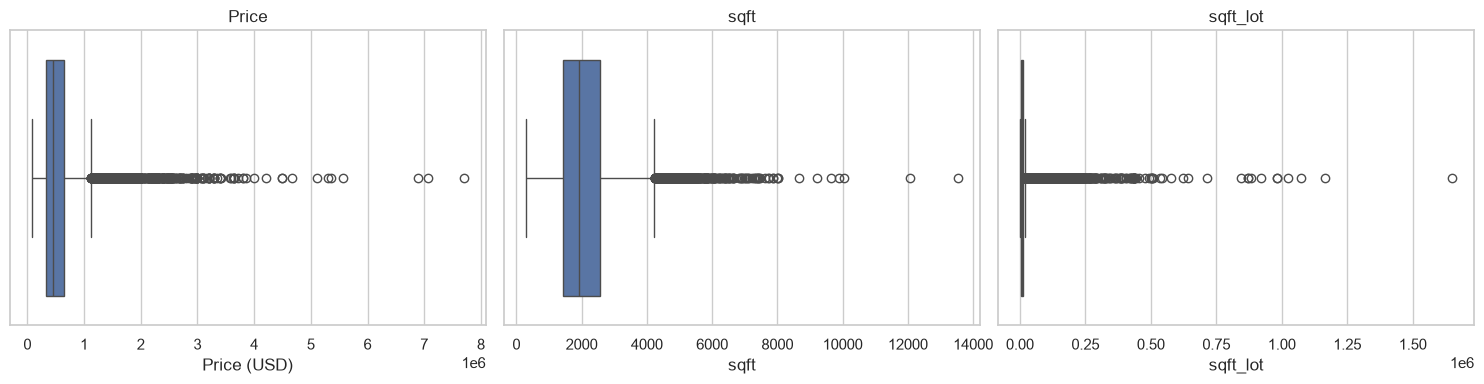

In [96]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(x=df_clean["price"], ax=axes[0])
axes[0].set_title("Price")
axes[0].set_xlabel("Price (USD)")

sns.boxplot(x=df_clean["sqft_living"], ax=axes[1])
axes[1].set_title("sqft")
axes[1].set_xlabel("sqft")

sns.boxplot(x=df_clean["sqft_lot"], ax=axes[2])
axes[2].set_title("sqft_lot")
axes[2].set_xlabel("sqft_lot")

plt.tight_layout()
save_fig("02_b4Percentile_values")
plt.show()

In [97]:
price = df_clean["price"]

# IQR rule
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
iqr_outliers = (price < q1 - 1.5 * iqr) | (price > q3 + 1.5 * iqr)

# Percentile rule
p01, p99 = price.quantile([0.01, 0.99])
pct_outliers = (price < p01) | (price > p99)

print(f"IQR rule:        keep {q1 - 1.5 * iqr:,.1f} to {q3 + 1.5 * iqr:,.1f} USD -> removes {iqr_outliers.sum():,} listings")
print(f"Percentile rule: keep {p01:,.1f} to {p99:,.1f} USD -> removes {pct_outliers.sum():,} listings")

IQR rule:        keep -162,625.0 to 1,129,575.0 USD -> removes 1,146 listings
Percentile rule: keep 153,500.4 to 1,964,400.0 USD -> removes 434 listings


In [98]:
rows_before = len(df_clean)

# 1) Remove listings without a price (our target variable)
df_clean = df_clean.dropna(subset=["price"])
print(f"Removed {rows_before - len(df_clean):,} listings without a price")


def within_percentiles(series, low=0.01, high=0.99):
    # True for values between the low and high percentiles. Missing values are kept (True):
    # we do not want to delete a row just because one of the columns is unknown.
    lower, upper = series.quantile([low, high])
    return series.isna() | series.between(lower, upper)


# 2) Percentile rule on the three main numeric columns. & means "AND": all three must be OK
keep = (
    within_percentiles(df_clean["price"])
    & within_percentiles(df_clean["sqft_living"])
    & within_percentiles(df_clean["sqft_lot"])
)
rows_before_outliers = len(df_clean)
df_clean = df_clean[keep].reset_index(drop=True)
print(f"Removed {rows_before_outliers - len(df_clean):,} outlier listings")
print(f"Rows left: {len(df_clean):,}")

Removed 0 listings without a price
Removed 1,140 outlier listings
Rows left: 20,473


Figure saved to ..\figures\03_new_values.png


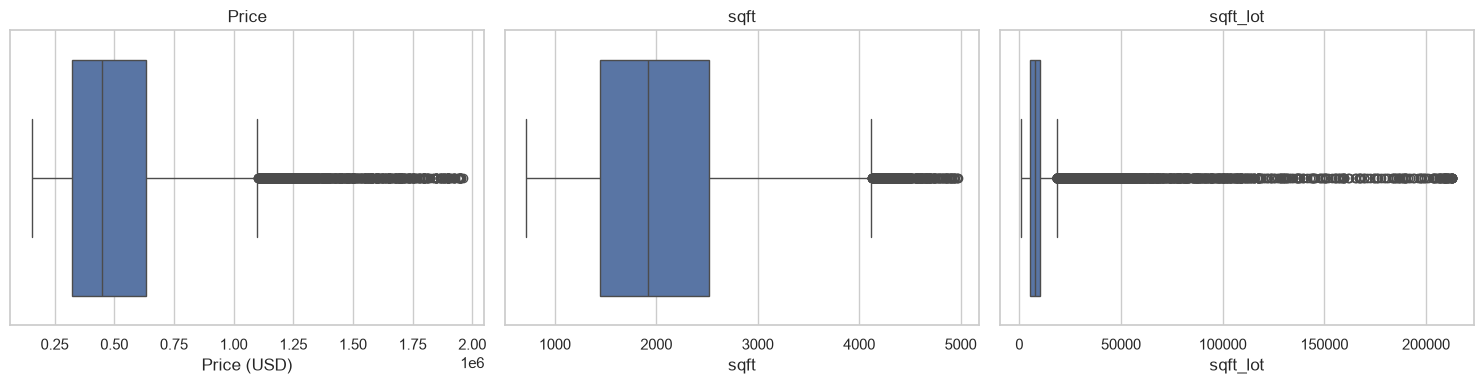

In [99]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(x=df_clean["price"], ax=axes[0])
axes[0].set_title("Price")
axes[0].set_xlabel("Price (USD)")

sns.boxplot(x=df_clean["sqft_living"], ax=axes[1])
axes[1].set_title("sqft")
axes[1].set_xlabel("sqft")

sns.boxplot(x=df_clean["sqft_lot"], ax=axes[2])
axes[2].set_title("sqft_lot")
axes[2].set_xlabel("sqft_lot")

plt.tight_layout()
save_fig("03_new_values")
plt.show()

In [100]:
missing_report(df_clean).head(12)

,n_missing,pct_missing
id,0,0.00
date,0,0.00
price,0,0.00
bedrooms,0,0.00
bathrooms,0,0.00
sqft_living,0,0.00
sqft_lot,0,0.00
floors,0,0.00
condition,0,0.00
grade,0,0.00


In [101]:
# Before / after comparison
comparison = pd.DataFrame(
    {
        "raw": [
            len(df),
            df.shape[1],
            df.select_dtypes("number").shape[1],
            df.isna().mean().mean() * 100,
            df.memory_usage(deep=True).sum() / 1e6,
        ],
        "clean": [
            len(df_clean),
            df_clean.shape[1],
            df_clean.select_dtypes("number").shape[1],
            df_clean.isna().mean().mean() * 100,
            df_clean.memory_usage(deep=True).sum() / 1e6,
        ],
    },
    index=["rows", "columns", "numeric columns", "average % missing", "memory (MB)"],
)
comparison

,raw,clean
rows,"21,613.00","20,473.00"
columns,21.00,19.00
numeric columns,20.00,18.00
average % missing,0.00,0.00
memory (MB),4.84,3.11


In [102]:
clean_path = DATA_DIR / "kc_houses_data_clean.csv"
df_clean.to_csv(clean_path, index=False)
print(f"Clean data saved to {clean_path} ({clean_path.stat().st_size / 1e6:.1f} MB)")

Clean data saved to ..\data\kc_houses_data_clean.csv (2.1 MB)


Exploratory Data Analysis (EDA)

First we add some columns we need for the analysis: living area in m2, price per sqft, and zipcode as text (we take it as a location, not a number).

In [103]:
SQFT_PER_M2 = 10.7639

df_clean["living_area_m2"] = df_clean["sqft_living"] / SQFT_PER_M2
df_clean["price_per_sqft"] = df_clean["price"] / df_clean["sqft_living"]
df_clean["zipcode"] = df_clean["zipcode"].astype(str)

df_clean[["price", "sqft_living", "living_area_m2", "price_per_sqft", "zipcode"]].head()

,price,sqft_living,living_area_m2,price_per_sqft,zipcode
0,"221,900.00",1180,109.63,188.05,98178
1,"538,000.00",2570,238.76,209.34,98125
2,"180,000.00",770,71.54,233.77,98028
3,"604,000.00",1960,182.09,308.16,98136
4,"510,000.00",1680,156.08,303.57,98074


Descriptive Statistic: 

The mean price (519k USD) is higher than the median (450k USD) because a few very expensive houses pull it up, so we use the median as the typical price. A typical house has 178 m2, 3 bedrooms and was built in 1974.

Bedrooms goes from 0 to 33. 33 is probably a typo (should be 3).

In [104]:
key_numeric = ["price", "price_per_sqft", "living_area_m2", "bedrooms", "bathrooms", "floors", "grade", "yr_built"]

stats = df_clean[key_numeric].describe().T
stats["skewness"] = df_clean[key_numeric].skew()
stats

,count,mean,std,min,25%,50%,75%,max,skewness
price,"20,473.00","518,882.24","276,391.72","153,503.00","325,000.00","450,000.00","635,000.00","1,960,000.00",1.72
price_per_sqft,"20,473.00",260.34,104.10,87.71,181.95,243.04,314.56,810.14,1.17
living_area_m2,"20,473.00",190.72,74.30,66.89,134.71,178.37,234.12,461.73,0.79
bedrooms,"20,473.00",3.39,0.90,0.00,3.00,3.00,4.00,33.00,2.24
bathrooms,"20,473.00",2.10,0.72,0.00,1.75,2.25,2.50,7.50,0.23
floors,"20,473.00",1.48,0.53,1.00,1.00,1.50,2.00,3.50,0.60
grade,"20,473.00",7.63,1.09,4.00,7.00,7.00,8.00,13.00,0.74
yr_built,"20,473.00","1,970.84",29.18,"1,900.00","1,952.00","1,974.00","1,996.00","2,015.00",-0.47


Univertiate analysis: numerical variables

How is the price distributed? We plot it in normal scale and log scale because the price is skewed.

Figure saved to ..\figures\04_price_distribution.png


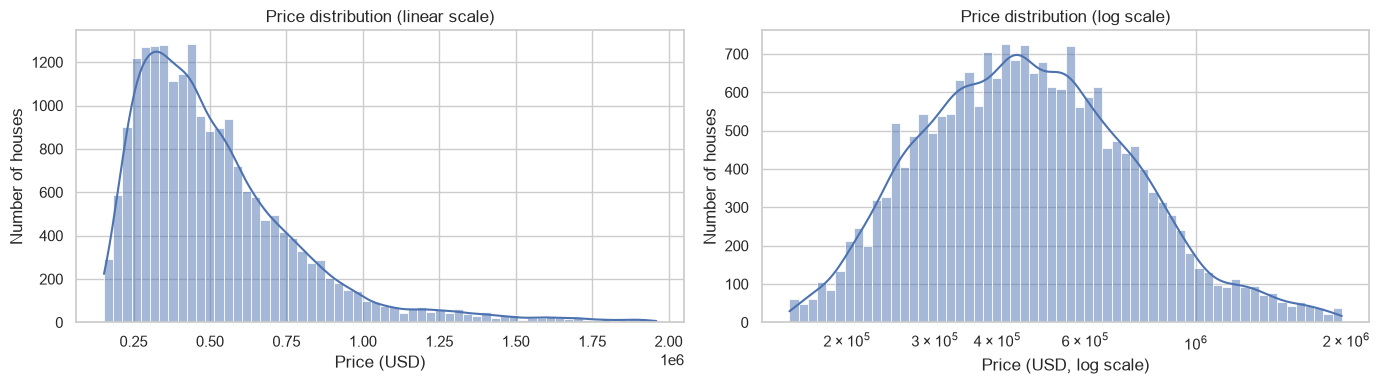

In [105]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df_clean["price"], bins=60, kde=True, ax=axes[0])
axes[0].set_title("Price distribution (linear scale)")
axes[0].set_xlabel("Price (USD)")
axes[0].set_ylabel("Number of houses")

sns.histplot(df_clean["price"], bins=60, kde=True, log_scale=True, ax=axes[1])
axes[1].set_title("Price distribution (log scale)")
axes[1].set_xlabel("Price (USD, log scale)")
axes[1].set_ylabel("Number of houses")

plt.tight_layout()
save_fig("04_price_distribution")
plt.show()

In normal scale most houses are on the left. In log scale it looks like a normal (bell) shape, so for Day 2 it makes sense to predict log(price).

How big are the houses and how much is a sqft?

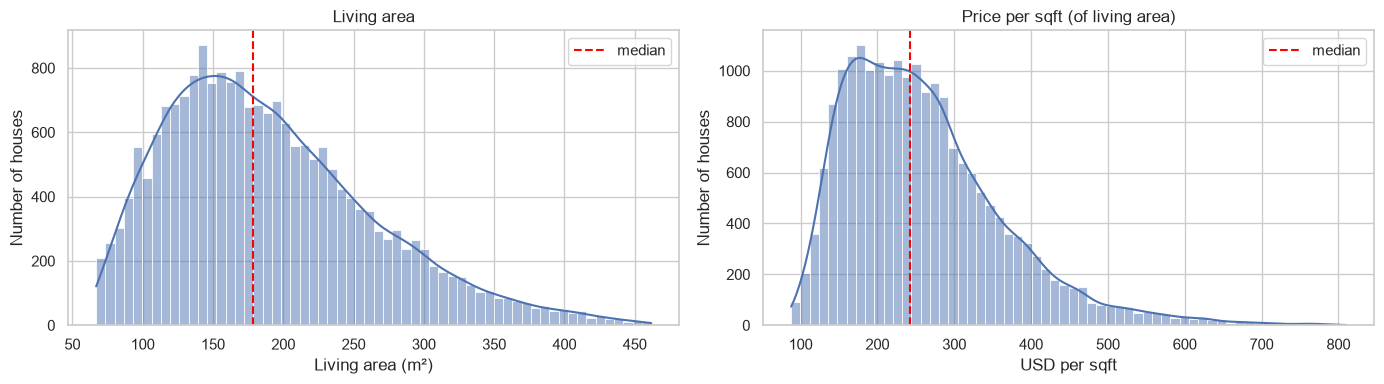

In [106]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df_clean["living_area_m2"], bins=60, kde=True, ax=axes[0])
axes[0].axvline(df_clean["living_area_m2"].median(), color="red", linestyle="--", label="median")
axes[0].set_title("Living area")
axes[0].set_xlabel("Living area (m²)")
axes[0].set_ylabel("Number of houses")
axes[0].legend()

sns.histplot(df_clean["price_per_sqft"], bins=60, kde=True, ax=axes[1])
axes[1].axvline(df_clean["price_per_sqft"].median(), color="red", linestyle="--", label="median")
axes[1].set_title("Price per sqft (of living area)")
axes[1].set_xlabel("USD per sqft")
axes[1].set_ylabel("Number of houses")
axes[1].legend()

plt.tight_layout()
plt.show()

Univartiate analysis: categorical variables

What kind of houses are sold? Condition (1-5) and grade (1-13) are ratings given by the county, so we keep them in order.

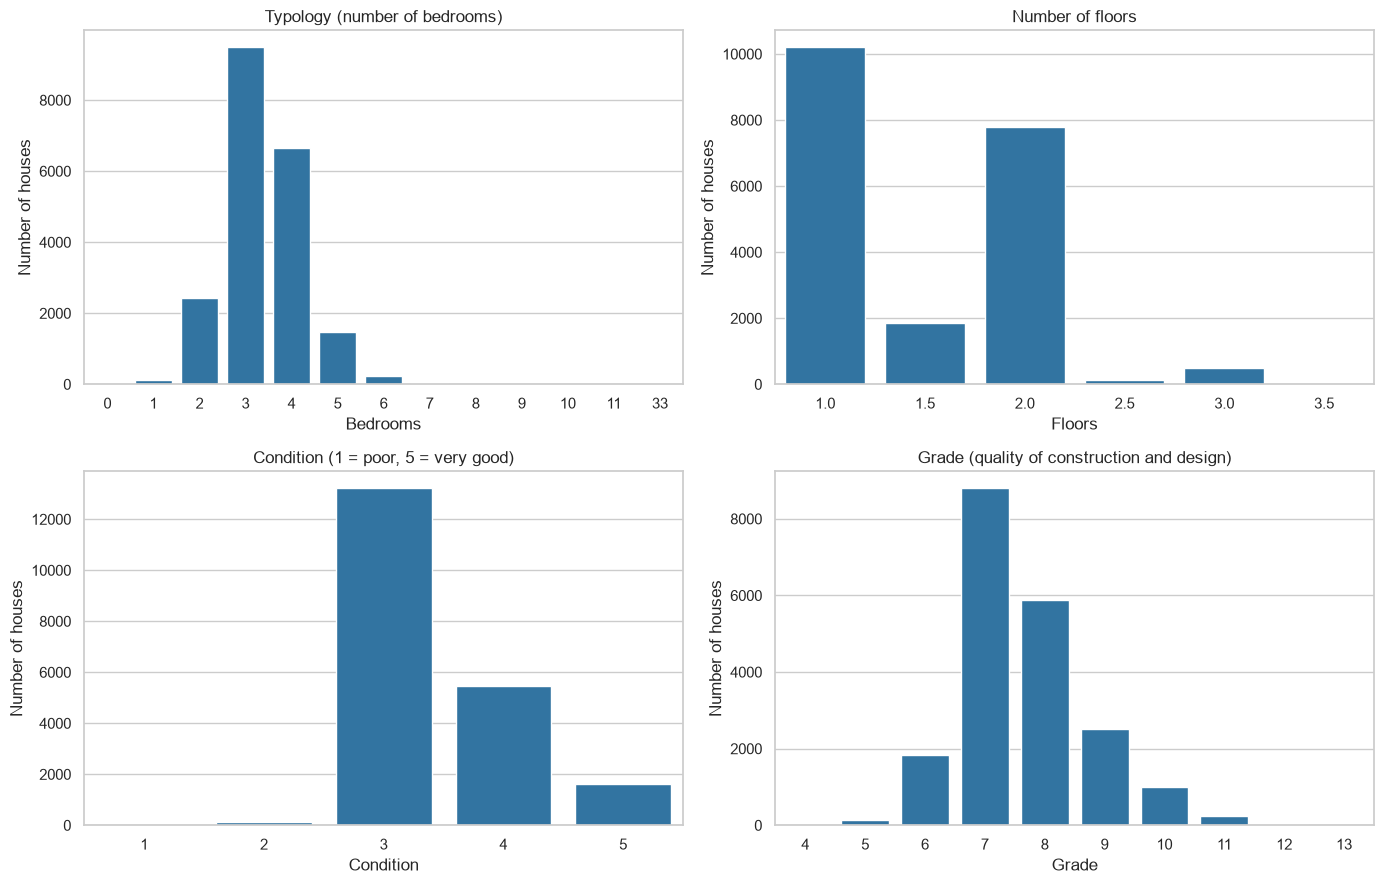

In [107]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.countplot(data=df_clean, x="bedrooms", color="tab:blue", ax=axes[0, 0])
axes[0, 0].set_title("Typology (number of bedrooms)")
axes[0, 0].set_xlabel("Bedrooms")

sns.countplot(data=df_clean, x="floors", color="tab:blue", ax=axes[0, 1])
axes[0, 1].set_title("Number of floors")
axes[0, 1].set_xlabel("Floors")

sns.countplot(data=df_clean, x="condition", color="tab:blue", ax=axes[1, 0])
axes[1, 0].set_title("Condition (1 = poor, 5 = very good)")
axes[1, 0].set_xlabel("Condition")

sns.countplot(data=df_clean, x="grade", color="tab:blue", ax=axes[1, 1])
axes[1, 1].set_title("Grade (quality of construction and design)")
axes[1, 1].set_xlabel("Grade")

for ax in axes.flat:
    ax.set_ylabel("Number of houses")

plt.tight_layout()
plt.show()

Most houses have 3 or 4 bedrooms, 1 or 2 floors, condition 3 and grade 7 or 8.

Which zipcodes are in the data?

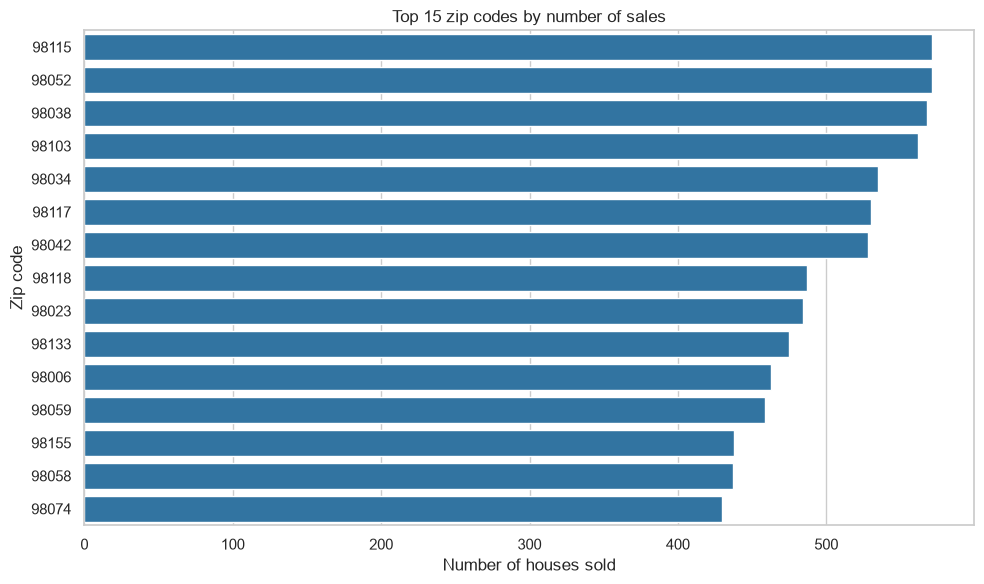

The dataset has 70 zip codes
The top 15 zip codes contain 37% of all houses


In [108]:
top_zipcodes = df_clean["zipcode"].value_counts().head(15)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top_zipcodes.values, y=top_zipcodes.index, color="tab:blue", ax=ax)
ax.set_title("Top 15 zip codes by number of sales")
ax.set_xlabel("Number of houses sold")
ax.set_ylabel("Zip code")
plt.tight_layout()
plt.show()

print(f"The dataset has {df_clean['zipcode'].nunique()} zip codes")
print(f"The top 15 zip codes contain {top_zipcodes.sum() / len(df_clean):.0%} of all houses")


Bivariate analysis:

Do bigger houses cost more? We use a sample of 5000 houses and log scale on both axes.

Figure saved to ..\figures\05_area_vs_price.png


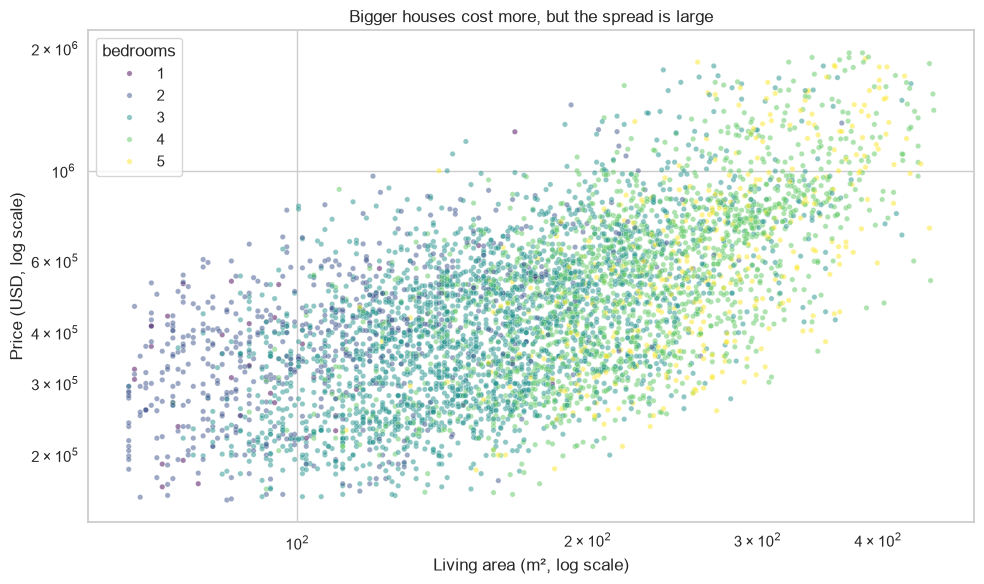

In [109]:
sample = df_clean.sample(5000, random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=sample[sample["bedrooms"].between(1, 5)], x="living_area_m2", y="price",
                hue="bedrooms", palette="viridis", alpha=0.5, s=15, ax=ax)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Bigger houses cost more, but the spread is large")
ax.set_xlabel("Living area (m², log scale)")
ax.set_ylabel("Price (USD, log scale)")
plt.tight_layout()
save_fig("05_area_vs_price")
plt.show()

Location is also important.

Figure saved to ..\figures\06_price_per_sqft_by_zipcode.png


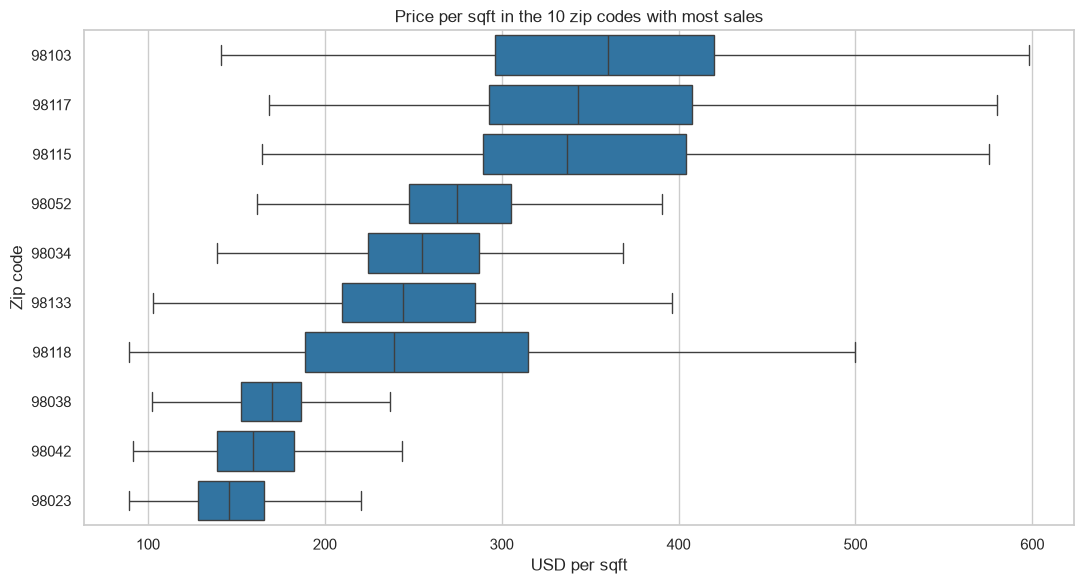

In [110]:
top10_zipcodes = df_clean["zipcode"].value_counts().head(10).index
in_top10 = df_clean[df_clean["zipcode"].isin(top10_zipcodes)]

# order from most to least expensive
zip_order = in_top10.groupby("zipcode")["price_per_sqft"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=in_top10, x="price_per_sqft", y="zipcode", order=zip_order,
            showfliers=False, color="tab:blue", ax=ax)
ax.set_title("Price per sqft in the 10 zip codes with most sales")
ax.set_xlabel("USD per sqft")
ax.set_ylabel("Zip code")
plt.tight_layout()
save_fig("06_price_per_sqft_by_zipcode")
plt.show()

The most expensive zipcode is about 2.5 times more expensive per sqft than the cheapest one.

Some areas are more expensive than others, so we compare each house only with houses in the same zipcode. A value of 1 means a normal price for that area, 1.2 means 20% more expensive and 0.8 means 20% cheaper.

In [111]:
zip_median = df_clean.groupby("zipcode")["price_per_sqft"].transform("median")
df_clean["relative_price"] = df_clean["price_per_sqft"] / zip_median

df_clean["relative_price"].describe()

count   20,473.00
mean         1.04
std          0.26
min          0.27
25%          0.87
50%          1.00
75%          1.15
max          4.57
Name: relative_price, dtype: float64

Does the grade change the value? Median relative price for each grade, the red line is 1 (same as the zipcode median).

Figure saved to ..\figures\07_grade_vs_price.png


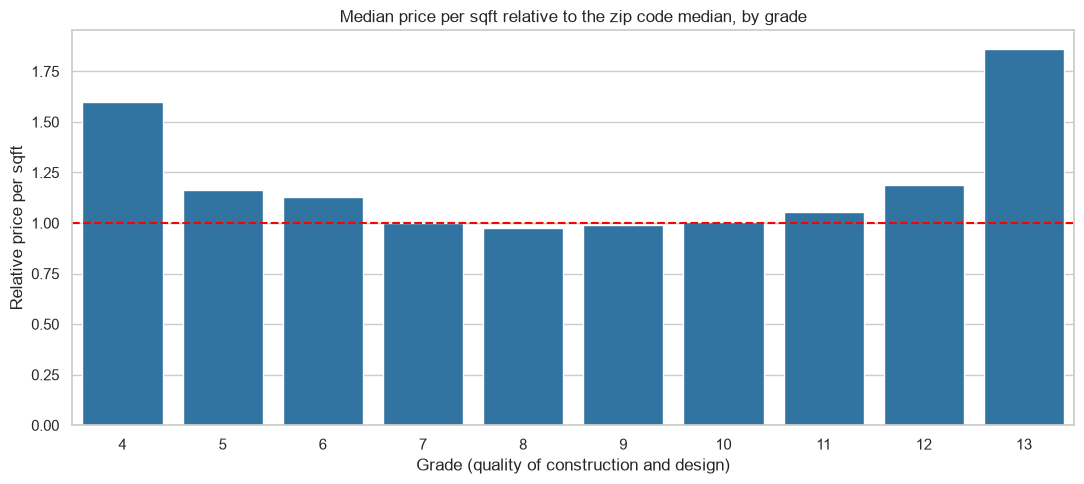

,median,count
grade,,
4,1.60,8
5,1.16,149
6,1.13,1826
7,1.00,8796
8,0.98,5885
9,0.99,2509
10,1.01,1011
11,1.05,253
12,1.19,35


In [112]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=df_clean, x="grade", y="relative_price",
            estimator="median", errorbar=None, color="tab:blue", ax=ax)
ax.axhline(1, color="red", linestyle="--")
ax.set_title("Median price per sqft relative to the zip code median, by grade")
ax.set_xlabel("Grade (quality of construction and design)")
ax.set_ylabel("Relative price per sqft")
plt.tight_layout()
save_fig("07_grade_vs_price")
plt.show()

df_clean.groupby("grade")["relative_price"].agg(["median", "count"])

Grades 7-10 are around 1, but low grades (5-6) and high grades (12-13) are higher. This is probably because of size: low grade houses are small. The total price still goes up with grade. Grade 4 and 13 have very few houses, so we ignore them.


Basement and renovation: we make two True/False columns and use melt to plot them together.

In [113]:
df_clean["has_basement"] = df_clean["sqft_basement"] > 0
df_clean["was_renovated"] = df_clean["yr_renovated"] > 0

features_long = df_clean.melt(
    id_vars="relative_price",
    value_vars=["has_basement", "was_renovated"],
    var_name="feature",
    value_name="has_feature",
)
features_long.head()

,relative_price,feature,has_feature
0,1.06,has_basement,False
1,0.80,has_basement,True
2,1.05,has_basement,False
3,0.96,has_basement,True
4,1.19,has_basement,False


Figure saved to ..\figures\08_features_vs_price.png


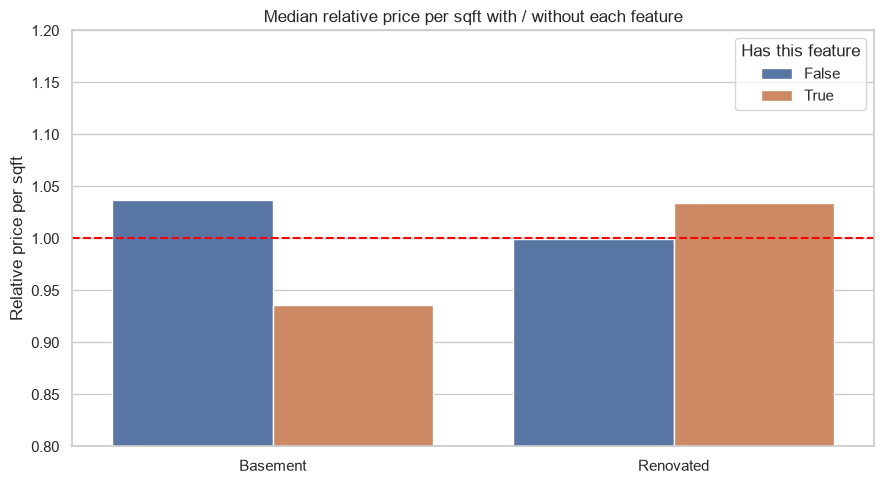

has_basement    0.39
was_renovated   0.04
dtype: float64

In [114]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=features_long, x="feature", y="relative_price", hue="has_feature",
            estimator="median", errorbar=None, ax=ax)
ax.axhline(1, color="red", linestyle="--")
ax.set_ylim(0.8, 1.2)
ax.set_title("Median relative price per sqft with / without each feature")
ax.set_xlabel("")
ax.set_xticks(range(2), ["Basement", "Renovated"])
ax.set_ylabel("Relative price per sqft")
ax.legend(title="Has this feature")
plt.tight_layout()
save_fig("08_features_vs_price")
plt.show()

df_clean[["has_basement", "was_renovated"]].mean()

Houses with a basement are a bit cheaper per sqft than other houses in the same area. These houses are also usually older.

Very few houses are renovated, and they are a bit more expensive than other houses in their area, even though they are old. This does not prove that renovation causes the higher price. 

Next, we check if older or newer houses are more expensive.

Figure saved to ..\figures\09_period_vs_price.png


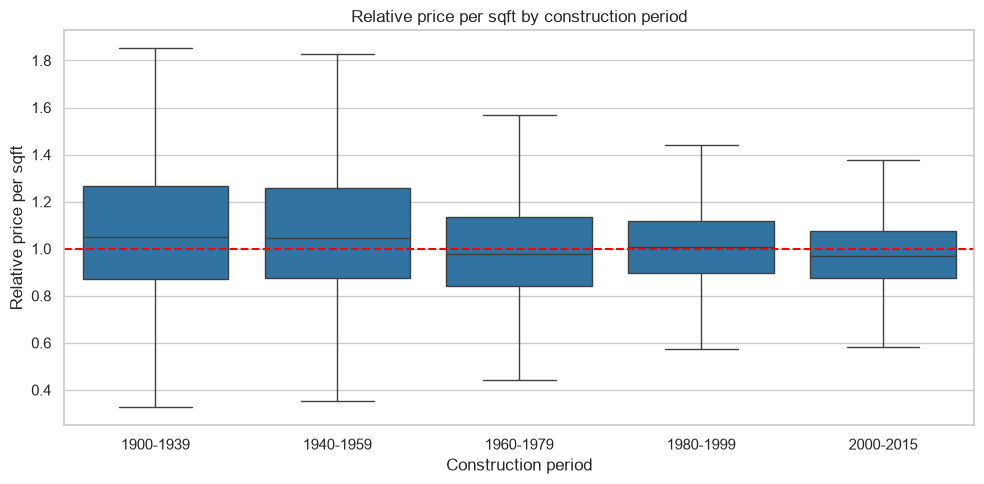

construction_period
1900-1939    2998
1940-1959    3973
1960-1979    4815
1980-1999    4333
2000-2015    4354
Name: count, dtype: int64

In [115]:
df_clean["construction_period"] = pd.cut(
    df_clean["yr_built"],
    bins=[1899, 1939, 1959, 1979, 1999, 2015],
    labels=["1900-1939", "1940-1959", "1960-1979", "1980-1999", "2000-2015"],
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df_clean, x="construction_period", y="relative_price", showfliers=False, color="tab:blue", ax=ax)
ax.axhline(1, color="red", linestyle="--")
ax.set_title("Relative price per sqft by construction period")
ax.set_xlabel("Construction period")
ax.set_ylabel("Relative price per sqft")
plt.tight_layout()
save_fig("09_period_vs_price")
plt.show()

df_clean["construction_period"].value_counts().sort_index()

Houses built before 1960 are a bit above their zipcode, newer ones are around 1 or a bit below. Old houses also have the biggest spread. It could be because old houses are smaller, or because of their character or plot, we cannot tell from this data.

Condition and number of floors, side by side with the same y axis.

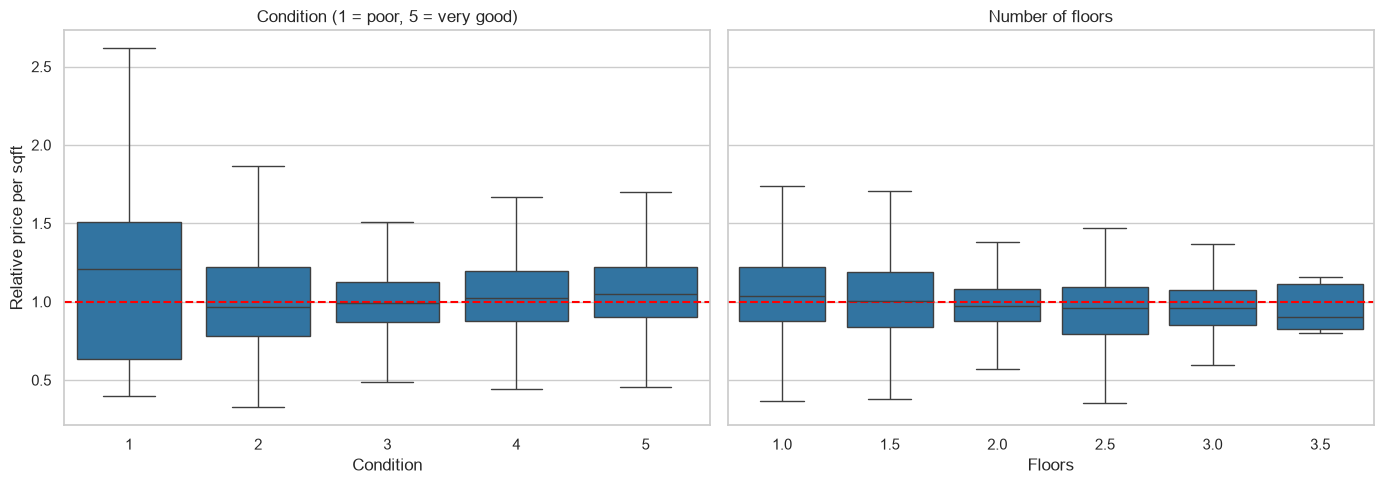

In [116]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

sns.boxplot(data=df_clean, x="condition", y="relative_price", showfliers=False,
            color="tab:blue", ax=axes[0])
axes[0].set_title("Condition (1 = poor, 5 = very good)")
axes[0].set_xlabel("Condition")
axes[0].set_ylabel("Relative price per sqft")

sns.boxplot(data=df_clean, x="floors", y="relative_price", showfliers=False,
            color="tab:blue", ax=axes[1])
axes[1].set_title("Number of floors")
axes[1].set_xlabel("Floors")

for ax in axes:
    ax.axhline(1, color="red", linestyle="--")

plt.tight_layout()
plt.show()

Better condition has a slightly higher relative price. One floor houses are the most expensive per sqft and two floor houses a bit cheaper, again probably because of size.

In general price per sqft is higher for small houses, so for Day 2 it is better to predict the total price (log) and use the area as an input.